Etude des Mousses / Chaussure via le jeu de données Askew, Hill, Payne, Stewart, Charles & Brown (2026)
Deux questions : 
1)  chjaussure à technolgie avancée réduit-elle le cout energeituqe à chaque pente 
2) bénfice dimlinu-til quand la pente augmente comme en trail

Source : Askew, Hill, Payne, Stewart, Charles & Brown (2026), Université de Leeds. DOI 10.5518/1823

difference entre les chaussures sont la plaque de carbone et aussi la gémoetrie pas que la mousse

In [1]:
"""La nouvelle mousse améliore-t-elle la performance au trail"""

import sys
from pathlib import Path
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import pandas as pd


In [2]:
# Bloc 0 - Paramètre 
FICHIER = Path("Askew_et_al_data.xlsx")
DOSSIER_SORTIE = Path("resultats")
DOSSIER_SORTIE.mkdir(exist_ok=True)

NOUVELLE = "VF"         # chaussure nouvelle mousse / AFT
REFERENCE = "SF"        # chaussure de référence 
PENTES = {"Level": 0, "3%": 3, "6%":6, "9%":9}    # nom colonne selon pente en %

COULEURS = {NOUVELLE: "#2a6fdb", REFERENCE: "#9aa3ad"}   # utilisation pour ploter




In [3]:
# Bloc 1 - Chargement des données 
# Chargeme,nt et mise format "long" (1 ligne = 1 sujet x 1 chaussure x 1 pente)

def charger_donnees(fichier: Path) -> pd.DataFrame:
    brut = pd.read_excel(fichier, sheet_name="Gross metabolic rate", header=1)
    brut = brut.rename(columns={brut.columns[0]: "sujet"})

    # On va garder que les participants 
    brut = brut[brut["sujet"].astype(str).str.match(r"^P\d+_\d+$")]
    long = brut.melt(id_vars="sujet", var_name="condition", value_name="vo2")
    long[["pente_nom", "chaussure"]] = long["condition"].str.rsplit("_", n=1, expand=True)
    long["pente"] = long["pente_nom"].map(PENTES)
    long["vo2"] = pd.to_numeric(long["vo2"], errors="coerce")
    long = long.dropna(subset=["vo2"])
    return long[["sujet", "chaussure", "pente", "vo2"]].sort_values(["sujet", "pente", "chaussure"])

def charger_masses(fichier: Path) -> pd.DataFrame:
    m = pd.read_excel(fichier, sheet_name="Shoe masses", header=1)
    return m.dropna(how="all")

In [4]:
# Bloc 2 - Gain individuel
# Difference par sujet : gain en % = (REF - NOUVELLE) / REF × 100
# si positif =  nouvelle chaussure coûte MOINS d'énergie soit meilleure économie

def calculer_gains(long: pd.DataFrame) -> pd.DataFrame:

    large = long.pivot_table(index=["sujet", "pente"], columns="chaussure", values="vo2").dropna()
    large = large.reset_index()
    large["diff_abs"] = large[REFERENCE] - large[NOUVELLE] # en ml/min/kg
    large["gain_pct"] = large["diff_abs"] / large[REFERENCE] * 100 # %
    return large

# gain % = (SF − VF) / SF × 100.

In [5]:
# Bloc 3 - Tests appariés par pente 
# Nous utilisreons des tests appariés par pente (t de Student + Wilcoxon, taille d'effet dz, correction Holm)

def tests_par_pente(gains: pd.DataFrame) -> pd.DataFrame:
    lignes = []
    for pente, g in gains.groupby("pente"):
        n = len(g)
        d = g["diff_abs"]
        t, p_t = stats.ttest_rel(g[REFERENCE], g[NOUVELLE])
        w, p_w = stats.wilcoxon(g[REFERENCE], g[NOUVELLE])
        dz = d.mean() / d.std(ddof=1)       # taille effet test appariée
        ic = stats.t.interval(0.95, n-1, loc=g["gain_pct"].mean(), scale=stats.sem(g["gain_pct"]))

        lignes.append({
            "pente_%": pente, "n":n,
            f"{NOUVELLE}_moy": g[NOUVELLE].mean(), f"{REFERENCE}_moy": g[REFERENCE].mean(),
            "gain_moy_%": g["gain_pct"].mean(), "IC95_bas_%": ic[0], "IC95_haut_%" : ic[1], 
            "repondeurs" : f"{(g['gain_pct'] > 0).sum()}/{n}",
            "t": t, "p_ttest" : p_t, "p_wilcoxon" : p_w, "dz_Cohen" : dz,
        })

    res = pd.DataFrame(lignes)
    res["p_ttest_Holm"] = multipletests(res["p_ttest"], method="holm")[1]
    return res




In [6]:
# Bloc 4 - Modèles linéaire miste
# modele linaire mixte : vo2 ~ chaussure * pente + (1 | sujet)
# observation de l'interaction chaussure:pente voir si le bénéfice chanhe avec la pente 

def modele_mixte(long: pd.DataFrame):
    df = long.copy()
    df["chaussure"] = pd.Categorical(df["chaussure"], categories=[REFERENCE, NOUVELLE])
    modele = smf.mixedlm("vo2 ~ chaussure * pente", df, groups=df["sujet"]).fit(reml=True)
    return modele

def regression_gain_pente(gains: pd.DataFrame):
    """Le gain diminu-t-il avec la pente ? Modele mixte sur les gains individuels"""
    return smf.mixedlm("gain_pct ~ pente", gains, groups=gains["sujet"]).fit(reml=True)





In [7]:
# Bloc 5 - Figures 

def figure_vo2(long: pd.DataFrame, chemin: Path):
    fig, ax = plt.subplots(figsize=(7, 5))
    for ch, decal in [(REFERENCE, -.25), (NOUVELLE, .25)]:
        sous = long[long["chaussure"] == ch]

        # sujet individuels (points légers)
        ax.scatter(sous["pente"] + decal, sous["vo2"], s=14, alpha=.35, color=COULEURS[ch])

        # moyenne ± ET
        stat = sous.groupby("pente")["vo2"].agg(["mean", "std"])
        ax.errorbar(stat.index + decal, stat["mean"], yerr=stat["std"], fmt="o-",color=COULEURS[ch], lw=2, capsize=4, label=ch)
    
    ax.set_xticks(list(PENTES.values()))
    ax.set_xticklabels([f"{p} %" for p in PENTES.values()])
    ax.set_xlabel("Pente du tapis")
    ax.set_ylabel("Métabolimse brutt (ml O$_2$·min$^{-1}$·kg$^{-1}$)")
    ax.set_title("Cout métabolique selon la chaussure et la pente")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(chemin, dpi=200)
    plt.close(fig)


In [8]:
def figure_gain(gains: pd.DataFrame, res: pd.DataFrame, chemin:Path):
    fig, ax = plt.subplots(figsize=(7,4))

    # ligne par sujet => en mode spaghetti plot
    for _, s in gains.groupby("sujet"):
        ax.plot(s["pente"], s["gain_pct"], color="#bbbbbb", lw=1, alpha=.8, marker="o", ms=3)

    # moyenne + IC95
    ax.errorbar(res["pente_%"], res["gain_moy_%"], yerr=[res["gain_moy_%"] - res["IC95_bas_%"], res["IC95_haut_%"] - res["gain_moy_%"]], fmt="o-", color=COULEURS[NOUVELLE], lw=2.5, capsize=5, label="Moyenne ± IC95 %")

    for _, r in res.iterrows():
        etoile = "*" if r["p_ttest_Holm"] < 0.05 else "ns"
        ax.annotate(etoile, (r["pente_%"], r["IC95_haut_%"] + 0.3), ha="center", fontsize=11)

    ax.axhline(0, color="black", lw=.8)
    ax.set_xticks(list(PENTES.values()))
    ax.set_xticklabels([f"{p} %" for p in PENTES.values()])
    ax.set_xlabel("Pente du tapis")
    ax.set_ylabel(f"Gain d'économie {NOUVELLE} vs {REFERENCE} (%)\n(> 0 = moins d'O$_2$ consommé)")
    ax.set_title("Le bénéfice de la chaussure diminie-t-il en montée ?")
    ax.legend(frameon=False, loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(chemin, dpi=200)
    plt.close(fig)
    

In [9]:
# Bloc 6 = Principale 

def main():
    long = charger_donnees(FICHIER)
    masses = charger_masses(FICHIER)
    gains = calculer_gains(long)
    res = tests_par_pente(gains)
    mm = modele_mixte(long)
    mm_gain = regression_gain_pente(gains)

    # Sauvagardes 
    long.to_csv(DOSSIER_SORTIE / "donnees_format_long.csv", index=False)
    gains.to_csv(DOSSIER_SORTIE / "gains_par_sujet.csv", index=False)
    res.round(4).to_csv(DOSSIER_SORTIE / "tests_par_pente.csv", index=False)
    figure_vo2(long, DOSSIER_SORTIE / "fig1_vo2_par_pente.png")
    figure_gain(gains, res, DOSSIER_SORTIE / "fig2_gain_par_pente.png")

    # Résume des données 
    pd.set_option("display.width", 160)
    lignes = []
    lignes.append("=" * 78)
    lignes.append(f"ANALYSE : {NOUVELLE} (nouvelle mousse + plaque) vs {REFERENCE} - Askew et al. 2026")
    lignes.append("=" * 78)
    lignes.append(f"Sujets : {long['sujet'].nunique()} | Observations : {len(long)}")
    lignes.append("\n1) Tests appariés par pente (gain > 0 = VF plus économique)\n")
    lignes.append(res[["pente_%", "n", "gain_moy_%", "IC95_bas_%", "IC95_haut_%","repondeurs", "p_ttest", "p_ttest_Holm", "p_wilcoxon", "dz_Cohen"]].round(3).to_string(index=False))

    lignes.append("\n2) Modèle mixte : vo2 ~ chaussure * pente + (1|sujet)\n")
    lignes.append(str(mm.summary().tables[1]))
    inter = f"chaussure[T.{NOUVELLE}]:pente"
    lignes.append(f"\n -> Interaction chaussure×pente : {mm.params[inter]:+.3f} ml/min/kg par % de pente "f"(p = {mm.pvalues[inter]:.3f})")


    lignes.append("\n3) gain (%) en fonction de la pente : gain ~ pente = (1|sujet)\n")
    a, b = mm_gain.params["Intercept"], mm_gain.params["pente"]
    lignes.append(f"    gain(%) = {a:.2f} {b:+.3f} x pente    (p pente = {mm_gain.pvalues['pente']:.3f})")
    if b < 0:
        lignes.append(f"     -> pente extrapolée où le gain s'annule : ~{-a / b:.1f} %")


    m8 = masses[masses.iloc[:,0] == 8]
    if not m8.empty:
        dm = float(m8.iloc[0, 3])
        lignes.append(f"\n4) Masse : VF est plus lourde de ~{dm:.0f} g par chaussure (UK 8). " f"Avec la règle ~1 %/100 g par pied, cela pénaliserait VF d'environ " f"{dm / 100:.2f} % : le gain observé est donc obtenu MALGRÉ la masse.")
    lignes.append("\nLimites à garder en tête :")
    lignes.append("  - VF a une plaque carbone, pas SF : soit effet mousse et plaque confondus.")
    lignes.append("  - Economie de course sur tapis un peu different de ce qu'on retrouve en trail sur la poste de pied ""(technique, descentes, terrain, fatigue).")
    lignes.append("  - n = 12 (11 à 9%) : puissance limitée pour détecter de petits effets. ")
    lignes.append("  - Pentes positives uniquement => trail combinaison de montée et descente.")

    texte = "\n".join(lignes)
    print(texte)
    (DOSSIER_SORTIE / "resume_resultats.txt").write_text(texte, encoding='utf-8')
    print(f"\nFichiers enregistrés dans : {DOSSIER_SORTIE.resolve()}")

main()

ANALYSE : VF (nouvelle mousse + plaque) vs SF - Askew et al. 2026
Sujets : 12 | Observations : 94

1) Tests appariés par pente (gain > 0 = VF plus économique)

 pente_%  n  gain_moy_%  IC95_bas_%  IC95_haut_% repondeurs  p_ttest  p_ttest_Holm  p_wilcoxon  dz_Cohen
       0 12       4.220       2.418        6.023      11/12    0.000         0.001       0.002     1.483
       3 12       2.418       0.534        4.301       8/12    0.015         0.045       0.034     0.832
       6 12       1.050      -1.131        3.230       8/12    0.274         0.423       0.266     0.332
       9 11       0.434      -0.330        1.199       7/11    0.212         0.423       0.240     0.402

2) Modèle mixte : vo2 ~ chaussure * pente + (1|sujet)

                        Coef. Std.Err.       z  P>|z|  [0.025  0.975]
Intercept              37.725    0.847  44.517  0.000  36.064  39.386
chaussure[T.VF]        -1.583    0.389  -4.066  0.000  -2.346  -0.820
pente                   2.323    0.050  46.430  0

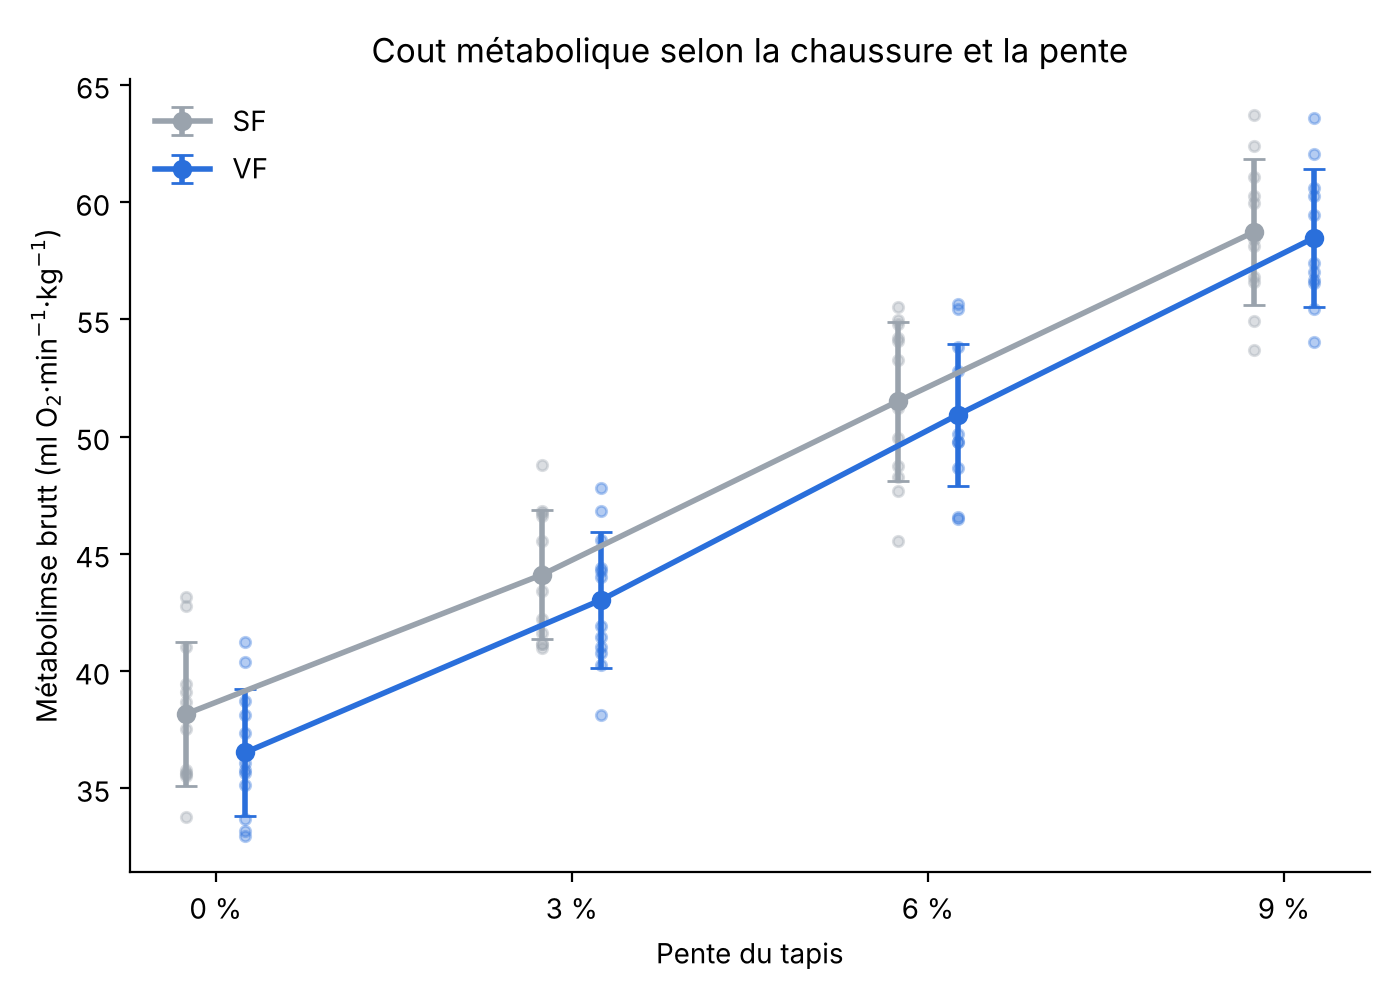

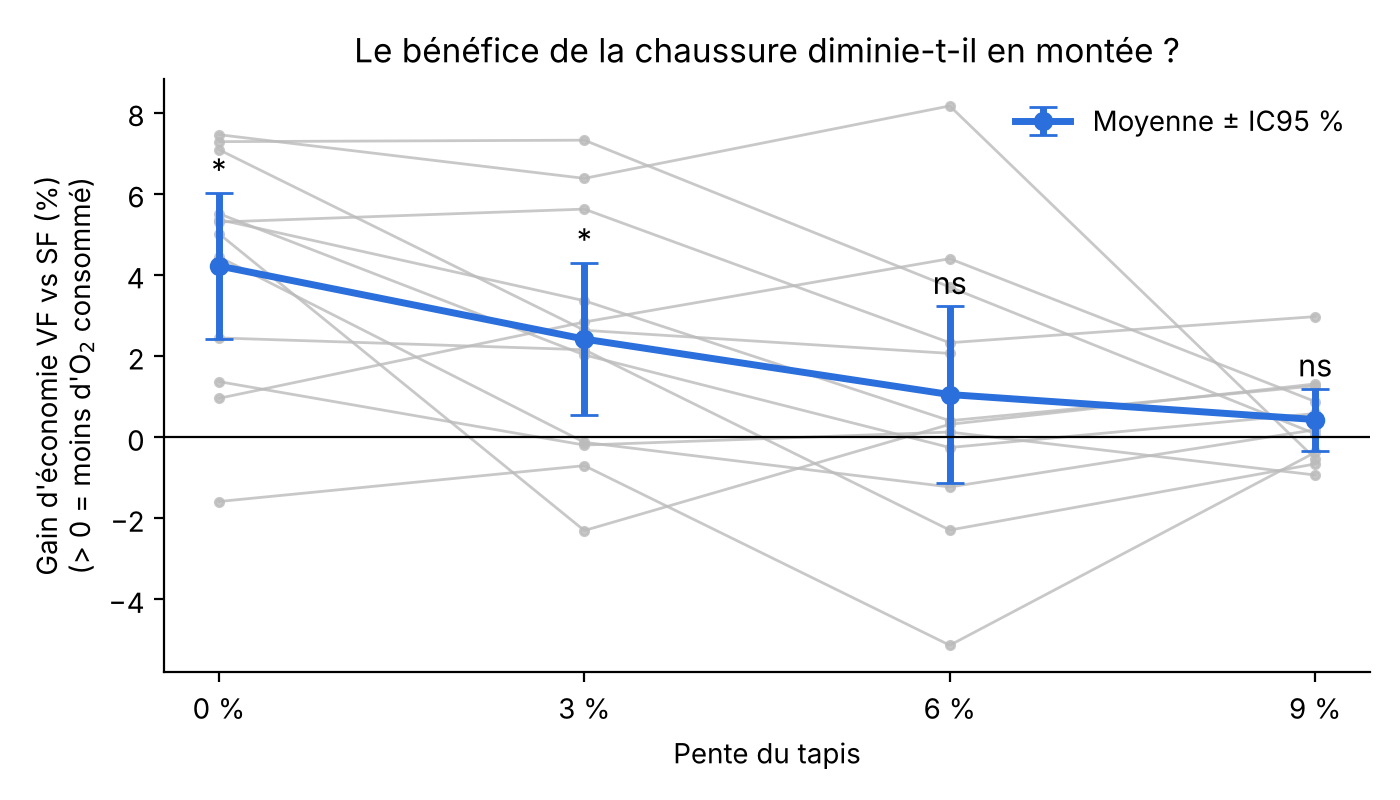

In [10]:
# Affichage des figures dans le notebook
from IPython.display import Image, display
display(Image("resultats/fig1_vo2_par_pente.png"))
display(Image("resultats/fig2_gain_par_pente.png"))